**Improvements vs. previous version:**
- ✅ **Diverse** augmentation (H/V flip, rotation ±20°, brightness, noise, distortion) via `albumentations`
- ✅ Each augmented image gets a **different random** transformation
- ✅ Idempotent: does not recopy originals that are already present
- ✅ Automatic anti-leakage check
- ✅ Augmentation-diversity visualization

⚠️ **Safety preserved**: only the train set is balanced. Val and Test keep their natural distribution.


In [1]:
# =============================================
# CELL 1: INSTALL DEPENDENCIES
# =============================================
!pip install -q albumentations opencv-python-headless pandas matplotlib seaborn tqdm scikit-learn
print("✅ Dependencies installed.")


✅ Dependencies installed.


In [2]:
# =============================================
# CELL 2: MOUNT GOOGLE DRIVE
# =============================================
from google.colab import drive
drive.mount('/content/drive')


Mounted at /content/drive


In [3]:
# ==============================================================================
# CELL 3: CONFIGURATION (ANTI-LEAKAGE SAFETY)
# ==============================================================================
import os
import cv2
import random
import numpy as np
import pandas as pd
import albumentations as A
from tqdm.notebook import tqdm

# ============================================================
# 🔧 USER CONFIGURATION — edit PROJECT_ROOT for your own setup
# ============================================================
PROJECT_ROOT = "/content/drive/MyDrive/lung_nodule_classification"

# ─── PATHS ───────────────────────────────────────────────────────────────────────────────────────────
# Loads EXCLUSIVELY the train.csv produced by Notebook 1
TRAIN_CSV_PATH = f"{PROJECT_ROOT}/master_dataset/train.csv"
BALANCED_DIR   = f"{PROJECT_ROOT}/balanced_train_only"
OUTPUT_CSV     = f"{PROJECT_ROOT}/master_dataset/train_balanced.csv"

# ─── PARAMETERS ───────────────────────────────────────────────────────────────────────────
TARGET_PER_CLASS = 12000
RANDOM_SEED      = 42

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

# ─── LOAD AND CHECK ───────────────────────────────────────────────────────────────────
if not os.path.exists(TRAIN_CSV_PATH):
    raise FileNotFoundError("❌ train.csv not found. Re-run Notebook 1.")

df_train = pd.read_csv(TRAIN_CSV_PATH)
print(f"✅ Train loaded: {len(df_train)} original images")
print("\n📊 Distribution BEFORE balancing:")
print(df_train['label'].value_counts().sort_index())

# Create output folders
for cls in [0, 1, 2]:
    os.makedirs(os.path.join(BALANCED_DIR, f"class_{cls}"), exist_ok=True)
print(f"\n📂 Output folders ready: {BALANCED_DIR}")


✅ Train loaded: 25852 original images

📊 Distribution BEFORE balancing:
label
0    11430
1     7346
2     7076
Name: count, dtype: int64

📂 Output folders ready: /content/drive/MyDrive/lung_nodule_classification/balanced_train_only


In [4]:
# ==============================================================================
# CELL 4: AUGMENTATION PIPELINE (MEDICAL-IMAGING SAFE)
# ==============================================================================
# Transformations chosen to preserve nodule semantics:
#   - H/V flips      : OK since patches are zoomed on the nodule
#   - Rotation       : ±20° (beyond that = interpolation artifacts)
#   - Brightness     : ±15% (scanner variability)
#   - Contrast       : ±15%
#   - Gaussian noise : light (simulates real CT noise)
#   - GridDistortion : very mild (tissue elasticity)
# Avoided: color jitter (grayscale images), aggressive elastic transform

augment = A.Compose([
    A.HorizontalFlip(p=0.5),
    A.VerticalFlip(p=0.5),
    A.Rotate(limit=20, border_mode=cv2.BORDER_REFLECT_101, p=0.7),
    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.5),
    A.GaussNoise(var_limit=(5.0, 20.0), p=0.3),
    A.GridDistortion(num_steps=5, distort_limit=0.1, border_mode=cv2.BORDER_REFLECT_101, p=0.2),
    A.ShiftScaleRotate(shift_limit=0.05, scale_limit=0.1, rotate_limit=0,
                       border_mode=cv2.BORDER_REFLECT_101, p=0.4),
])

print("✅ Augmentation pipeline defined:")
for t in augment.transforms:
    print(f"   • {t.__class__.__name__:30s} (p={t.p})")


✅ Augmentation pipeline defined:
   • HorizontalFlip                 (p=0.5)
   • VerticalFlip                   (p=0.5)
   • Rotate                         (p=0.7)
   • RandomBrightnessContrast       (p=0.5)
   • GaussNoise                     (p=0.3)
   • GridDistortion                 (p=0.2)
   • ShiftScaleRotate               (p=0.4)


/tmp/ipykernel_1144/87965034.py:18: UserWarning: Argument(s) 'var_limit' are not valid for transform GaussNoise
  A.GaussNoise(var_limit=(5.0, 20.0), p=0.3),
/usr/local/lib/python3.13/dist-packages/albumentations/core/validation.py:114: UserWarning: ShiftScaleRotate is a special case of Affine transform. Please use Affine transform instead.
  original_init(self, **validated_kwargs)


In [5]:
# ==============================================================================
# CELL 5: TRAIN-SET BALANCING WITH DIVERSE AUGMENTATION
# ==============================================================================
new_train_data = []

# Lightweight LRU-style cache to speed things up (avoids re-reading the same images repeatedly)
img_cache = {}
CACHE_MAX = 500

def get_img(path):
    if path not in img_cache:
        img_cache[path] = cv2.imread(path)
        if len(img_cache) > CACHE_MAX:
            # Drop the oldest entry (simple FIFO)
            img_cache.pop(next(iter(img_cache)))
    return img_cache[path]

for class_id in [0, 1, 2]:
    class_subset = df_train[df_train['label'] == class_id].copy()
    originals = class_subset.values.tolist()  # [path, label, source, patient_id]
    print(f"\n{'='*60}")
    print(f"🔄 Class {class_id}: {len(originals)} originals")
    print(f"{'='*60}")

    # ─── 1. COPY THE ORIGINALS (idempotent) ───────────────────────────────────────────────
    n_copied, n_skipped = 0, 0
    for item in tqdm(originals, desc=f"Copying Cls {class_id}"):
        src_path = item[0]
        filename = os.path.basename(src_path)
        dst_path = os.path.join(BALANCED_DIR, f"class_{class_id}", filename)

        if not os.path.exists(dst_path):
            img = cv2.imread(src_path)
            if img is None:
                print(f"⚠️  Unreadable image: {src_path}")
                continue
            cv2.imwrite(dst_path, img)
            n_copied += 1
        else:
            n_skipped += 1
        new_train_data.append([dst_path, class_id, item[2], item[3], 0])
    print(f"   📋 {n_copied} copied, {n_skipped} already present")

    # ─── 2. DIVERSE AUGMENTATION ───────────────────────────────────────────────
    num_to_augment = TARGET_PER_CLASS - len(originals)
    if num_to_augment <= 0:
        print(f"   ✓ No augmentation needed (already ≥ {TARGET_PER_CLASS})")
        continue

    print(f"   ➕ Augmentation: +{num_to_augment} images to generate")

    for i in tqdm(range(num_to_augment), desc=f"Aug Cls {class_id}"):
        parent_item = random.choice(originals)
        img = get_img(parent_item[0])
        if img is None:
            continue

        # Different random augmentation on every call
        img_aug = augment(image=img)['image']

        aug_filename = f"aug_cls{class_id}_{i:05d}_{os.path.basename(parent_item[0])}"
        aug_path = os.path.join(BALANCED_DIR, f"class_{class_id}", aug_filename)
        cv2.imwrite(aug_path, img_aug)
        new_train_data.append([aug_path, class_id, parent_item[2], parent_item[3], 1])

# ─── 3. SAVE THE MANIFEST ──────────────────────────────────────────
df_balanced = pd.DataFrame(
    new_train_data,
    columns=['path', 'label', 'source', 'patient_id', 'is_augmented']
)
df_balanced.to_csv(OUTPUT_CSV, index=False)
print(f"\n{'='*60}")
print(f"✅ Balancing complete: {len(df_balanced)} images total")
print(f"💾 Manifest: {OUTPUT_CSV}")
print(f"{'='*60}")
print(df_balanced.groupby(['label', 'is_augmented']).size().unstack(fill_value=0).rename(
    columns={0: 'Original', 1: 'Augmented'}, index={0: 'Non-Nodule', 1: 'Benign', 2: 'Malignant'}
))



🔄 Class 0: 11430 originals


Copying Cls 0:   0%|          | 0/11430 [00:00<?, ?it/s]

   📋 11430 copied, 0 already present
   ➕ Augmentation: +570 images to generate


Aug Cls 0:   0%|          | 0/570 [00:00<?, ?it/s]


🔄 Class 1: 7346 originals


Copying Cls 1:   0%|          | 0/7346 [00:00<?, ?it/s]

... (3 outputs left out)

Copying Cls 2:   0%|          | 0/7076 [00:00<?, ?it/s]

   📋 7076 copied, 0 already present
   ➕ Augmentation: +4924 images to generate


Aug Cls 2:   0%|          | 0/4924 [00:00<?, ?it/s]


✅ Balancing complete: 36000 images total
💾 Manifest: /content/drive/MyDrive/lung_nodule_classification/master_dataset/train_balanced.csv
is_augmented  Original  Augmented
label                            
Non-Nodule       11430        570
Benign            7346       4654
Malignant         7076       4924


In [6]:
# ==============================================================================
# CELL 6: ANTI-LEAKAGE CHECKS
# ==============================================================================
# 1. Every patient in the balanced set must come from the original train set
train_patients    = set(df_train['patient_id'].unique())
balanced_patients = set(df_balanced['patient_id'].unique())

assert balanced_patients.issubset(train_patients), \
    "❌ LEAKAGE: some balanced-set patients were not in the original train set!"
print(f"✅ No leakage: {len(balanced_patients)} patients ⊂ {len(train_patients)} train patients")

# 2. Check that each class reaches the target
counts = df_balanced['label'].value_counts().sort_index()
for cls in [0, 1, 2]:
    if counts.get(cls, 0) < TARGET_PER_CLASS:
        print(f"⚠️  Class {cls}: {counts.get(cls, 0)} < {TARGET_PER_CLASS}")
    else:
        print(f"✅ Class {cls}: {counts.get(cls, 0)} images")

# 3. Per-patient statistics
print(f"\n👥 Statistics per class:")
for cls in [0, 1, 2]:
    sub = df_balanced[df_balanced['label'] == cls]
    n_pat = sub['patient_id'].nunique()
    n_orig = (sub['is_augmented'] == 0).sum()
    n_aug  = (sub['is_augmented'] == 1).sum()
    ratio = n_aug / max(n_orig, 1)
    print(f"   Class {cls}: {n_pat} patients | {n_orig} orig + {n_aug} aug | aug/orig ratio = {ratio:.2f}")


✅ No leakage: 1061 patients ⊂ 1061 train patients
✅ Class 0: 12000 images
✅ Class 1: 12000 images
✅ Class 2: 12000 images

👥 Statistics per class:
   Class 0: 506 patients | 11430 orig + 570 aug | aug/orig ratio = 0.05
   Class 1: 425 patients | 7346 orig + 4654 aug | aug/orig ratio = 0.63
   Class 2: 378 patients | 7076 orig + 4924 aug | aug/orig ratio = 0.70


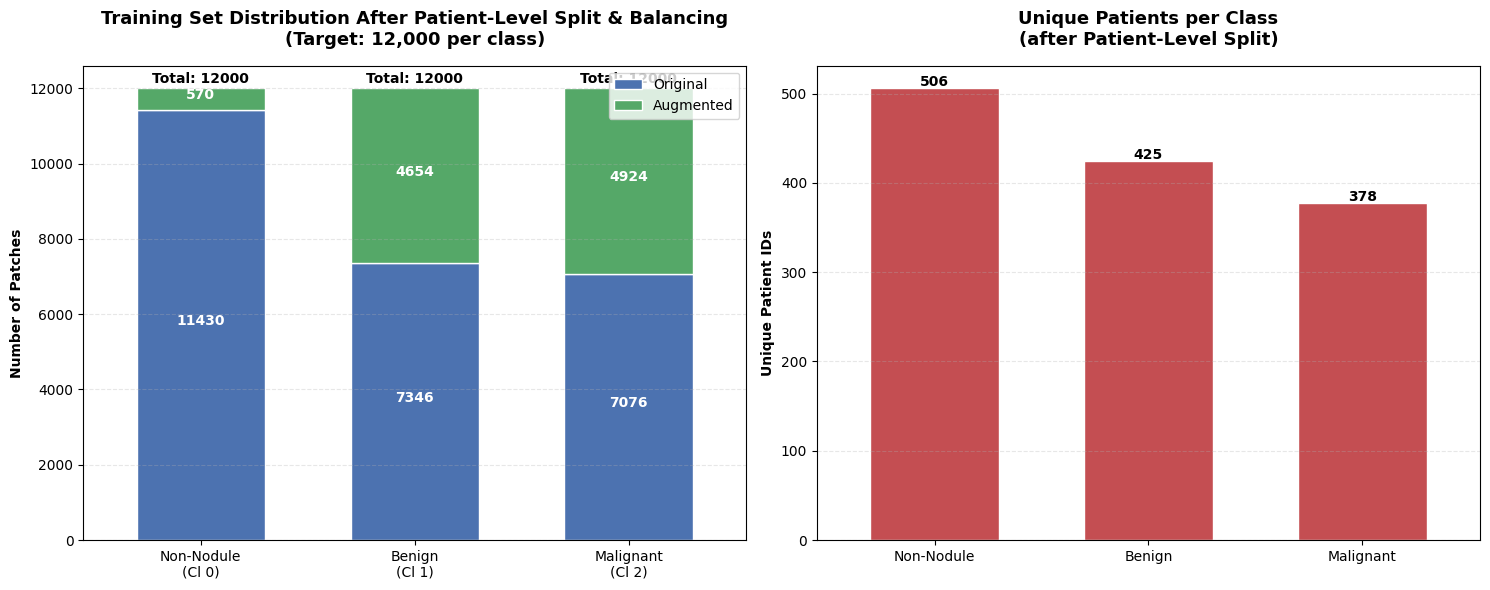

💾 Figure saved: /content/drive/MyDrive/lung_nodule_classification/master_dataset/balanced_train_distribution.png


In [7]:
# ==============================================================================
# CELL 7: DISTRIBUTION VISUALIZATION
# ==============================================================================
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# ─── (a) Stacked Original / Augmented distribution ────────────────────────────
counts = df_balanced.groupby(['label', 'is_augmented']).size().unstack(fill_value=0)
counts.columns = ['Original', 'Augmented']
counts.index = ['Non-Nodule\n(Cl 0)', 'Benign\n(Cl 1)', 'Malignant\n(Cl 2)']

counts.plot(kind='bar', stacked=True, ax=axes[0],
            color=['#4c72b0', '#55a868'], edgecolor='white', width=0.6)
axes[0].set_title('Training Set Distribution After Patient-Level Split & Balancing\n(Target: 12,000 per class)',
                  fontweight='bold', fontsize=13, pad=15)
axes[0].set_ylabel('Number of Patches', fontweight='bold')
axes[0].set_xlabel('')
axes[0].set_xticklabels(counts.index, rotation=0)
axes[0].legend(loc='upper right', frameon=True)

for i, (orig, aug) in enumerate(zip(counts['Original'], counts['Augmented'])):
    axes[0].text(i, orig/2, f'{orig}', ha='center', color='white', fontweight='bold')
    if aug > 300:
        axes[0].text(i, orig + aug/2, f'{aug}', ha='center', color='white', fontweight='bold')
    axes[0].text(i, orig + aug + 150, f'Total: {orig+aug}', ha='center', fontweight='bold')

axes[0].grid(axis='y', linestyle='--', alpha=0.3)

# ─── (b) Unique patients per class ────────────────────────────────────────────
patients_per_class = df_balanced.groupby('label')['patient_id'].nunique()
patients_per_class.index = ['Non-Nodule', 'Benign', 'Malignant']
patients_per_class.plot(kind='bar', ax=axes[1], color='#c44e52', edgecolor='white', width=0.6)
axes[1].set_title('Unique Patients per Class\n(after Patient-Level Split)',
                  fontweight='bold', fontsize=13, pad=15)
axes[1].set_ylabel('Unique Patient IDs', fontweight='bold')
axes[1].set_xlabel('')
axes[1].set_xticklabels(patients_per_class.index, rotation=0)
for i, v in enumerate(patients_per_class.values):
    axes[1].text(i, v + 2, str(v), ha='center', fontweight='bold')
axes[1].grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
out_path = f"{PROJECT_ROOT}/master_dataset/balanced_train_distribution.png"  # NOTE: fixed — was pointing to an unrelated "Article_Journal" folder
plt.savefig(out_path, dpi=300, bbox_inches='tight')
plt.show()
print(f"💾 Figure saved: {out_path}")


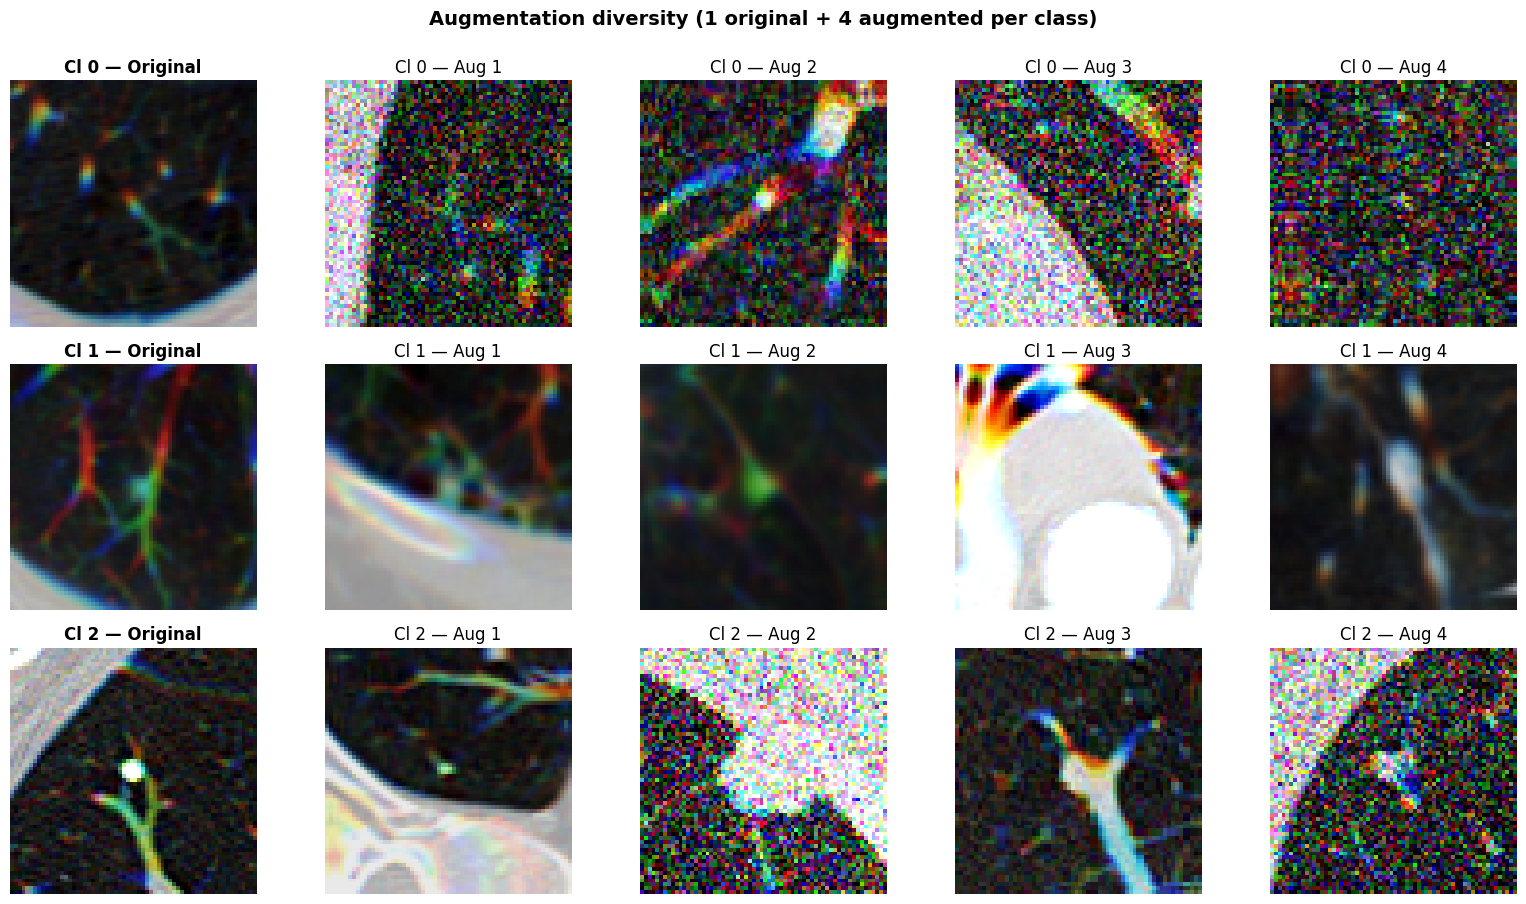

💾 Figure saved: /content/drive/MyDrive/lung_nodule_classification/master_dataset/augmentation_samples.png

👁️  Visually check that the 4 augmentations are indeed different from one another!


In [8]:
# ==============================================================================
# CELL 8: QUALITY CHECK — AUGMENTATION DIVERSITY
# ==============================================================================
# Shows 1 original image + 4 augmented versions for each class
# This allows a visual check that the transformations are varied

fig, axes = plt.subplots(3, 5, figsize=(16, 9))

for row, cls in enumerate([0, 1, 2]):
    sub = df_balanced[df_balanced['label'] == cls]

    # Find an original that has at least 4 derived augmentations
    sample_orig = sub[sub['is_augmented'] == 0].sample(1, random_state=42).iloc[0]
    sample_augs = sub[sub['is_augmented'] == 1].sample(4, random_state=cls).values.tolist()

    # Original
    img = cv2.imread(sample_orig['path'])
    if img is not None:
        axes[row, 0].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    axes[row, 0].set_title(f'Cl {cls} — Original', fontweight='bold')
    axes[row, 0].axis('off')

    # 4 augmentations
    for col, aug_row in enumerate(sample_augs, start=1):
        img = cv2.imread(aug_row[0])
        if img is not None:
            axes[row, col].imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        axes[row, col].set_title(f'Cl {cls} — Aug {col}')
        axes[row, col].axis('off')

plt.suptitle('Augmentation diversity (1 original + 4 augmented per class)',
             fontweight='bold', fontsize=14, y=1.00)
plt.tight_layout()
out_path = f"{PROJECT_ROOT}/master_dataset/augmentation_samples.png"  # NOTE: fixed, see Cell 7
plt.savefig(out_path, dpi=200, bbox_inches='tight')
plt.show()
print(f"💾 Figure saved: {out_path}")
print("\n👁️  Visually check that the 4 augmentations are indeed different from one another!")
